In [1]:
# Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load Dataset
file_path = 'https://raw.githubusercontent.com/Seunghyun19191/CIS_412_Airline_Satisfaction/main/train.csv'

df = pd.read_csv(file_path)

df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [3]:
######### Data Understanding #########

In [4]:
# Check Dataset Size
df.shape

(103904, 25)

In [5]:
# Check column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      1039

In [6]:
# Check missing values
df.isnull().sum()

,0
Unnamed: 0,0
id,0
Gender,0
Customer Type,0
Age,0
Type of Travel,0
Class,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0


In [7]:
# Summary Statistics
df.describe()

,Unnamed: 0,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103594.000000
mean,51951.500000,64924.210502,39.379706,1189.448375,2.729683,3.060296,2.756901,2.976883,3.202129,3.250375,3.439396,3.358158,3.382363,3.351055,3.631833,3.304290,3.640428,3.286351,14.815618,15.178678
std,29994.645522,37463.812252,15.114964,997.147281,1.327829,1.525075,1.398929,1.277621,1.329533,1.349509,1.319088,1.332991,1.288354,1.315605,1.180903,1.265396,1.175663,1.312273,38.230901,38.698682
min,0.000000,1.000000,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,25975.750000,32533.750000,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,51951.500000,64856.500000,40.000000,843.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,0.000000,0.000000
75%,77927.250000,97368.250000,51.000000,1743.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,5.000000,4.000000,12.000000,13.000000
max,103903.000000,129880.000000,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


In [8]:
## Exploratory Data Analysis (EDA) ##

In [9]:
# Satisfaction Distribution
print(df['satisfaction'].value_counts())

satisfaction
neutral or dissatisfied    58879
satisfied                  45025
Name: count, dtype: int64


In [10]:
# Satisfaction Percentage
print(df['satisfaction'].value_counts(normalize=True) * 100)

satisfaction
neutral or dissatisfied    56.666731
satisfied                  43.333269
Name: proportion, dtype: float64


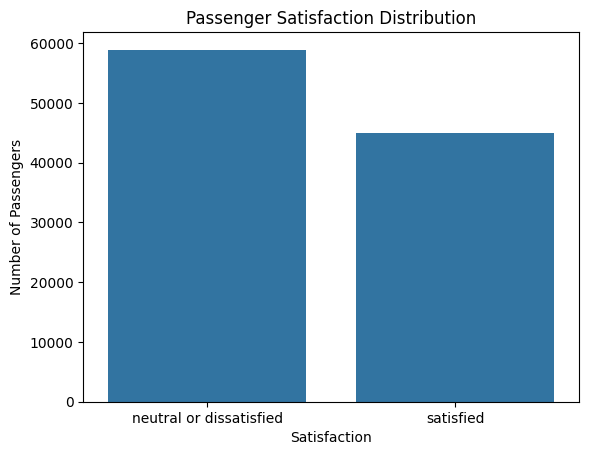

In [11]:
# 1. Satisfaction Distribution Chart

sns.countplot(data=df, x='satisfaction')

plt.title('Passenger Satisfaction Distribution')
plt.xlabel('Satisfaction')
plt.ylabel('Number of Passengers')

plt.show()

In [12]:
# Satisfaction by Travel Class

pd.crosstab(
    df['Class'],
    df['satisfaction'],
    normalize='index'
) * 100

satisfaction,neutral or dissatisfied,satisfied
Class,,
Business,30.574852,69.425148
Eco,81.386245,18.613755
Eco Plus,75.393648,24.606352


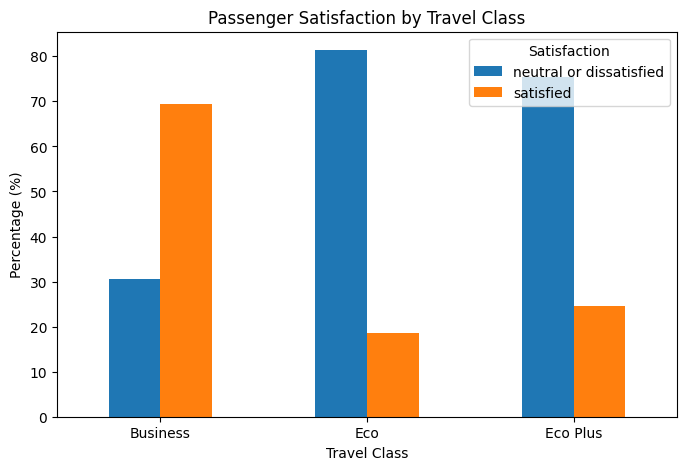

In [13]:
# 2. Satisfaction by Travel Class Visualization

class_satisfaction = pd.crosstab(
    df['Class'],
    df['satisfaction'],
    normalize='index'
) * 100

class_satisfaction.plot(kind='bar', figsize=(8, 5))

plt.title('Passenger Satisfaction by Travel Class')
plt.xlabel('Travel Class')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Satisfaction')

plt.show()

In [14]:
# Satisfaction by Seat Comfort

pd.crosstab(
    df['Seat comfort'],
    df['satisfaction'],
    normalize='index'
) * 100

satisfaction,neutral or dissatisfied,satisfied
Seat comfort,,
0,100.000000,0.000000
1,77.681159,22.318841
2,77.586091,22.413909
3,78.845742,21.154258
4,43.884779,56.115221
5,34.979222,65.020778


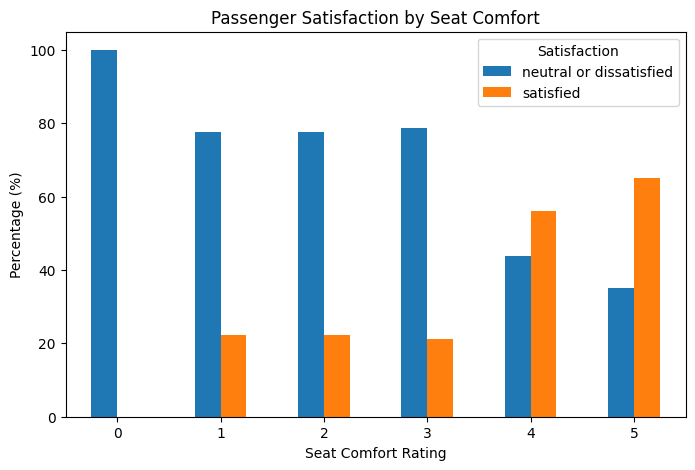

In [15]:
# 3. Satisfaction by Seat Comfort Visualization

seat_satisfaction = pd.crosstab(
    df['Seat comfort'],
    df['satisfaction'],
    normalize='index'
) * 100

seat_satisfaction.plot(kind='bar', figsize=(8, 5))

plt.title('Passenger Satisfaction by Seat Comfort')
plt.xlabel('Seat Comfort Rating')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Satisfaction')

plt.show()

In [16]:
# Satisfaction by Customer Type

pd.crosstab(
    df['Customer Type'],
    df['satisfaction'],
    normalize='index'
) * 100

satisfaction,neutral or dissatisfied,satisfied
Customer Type,,
Loyal Customer,52.270881,47.729119
disloyal Customer,76.334229,23.665771


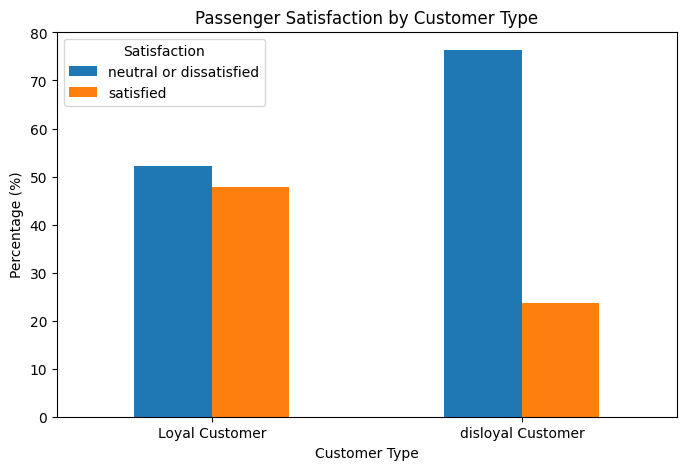

In [17]:
# 4. Satisfaction by Customer Type Visualization

customer_satisfaction = pd.crosstab(
    df['Customer Type'],
    df['satisfaction'],
    normalize='index'
) * 100

customer_satisfaction.plot(kind='bar', figsize=(8, 5))

plt.title('Passenger Satisfaction by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Satisfaction')

plt.show()

In [18]:
######### Data Preparation #########

In [19]:
# Remove unnecessary columns
## Both column has no relation with satisfaction


df_clean = df.drop(columns=['Unnamed: 0', 'id'])

df_clean.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [20]:
# Check duplicate records

df_clean.duplicated().sum()

np.int64(0)

In [21]:
# Separate Features and Target Variable

X = df_clean.drop(columns=['satisfaction'])
y = df_clean['satisfaction']

In [22]:
# Train/Test Split (80:20)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape

((83123, 22), (20781, 22))

In [23]:
# Check Missing Values in Training and Test Sets

X_train.isnull().sum()

,0
Gender,0
Customer Type,0
Age,0
Type of Travel,0
Class,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0


In [24]:
# Check Missing Values in Test Set

X_test.isnull().sum()

,0
Gender,0
Customer Type,0
Age,0
Type of Travel,0
Class,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0


In [25]:
# Calculate Median from Training Set

arrival_median = X_train['Arrival Delay in Minutes'].median()

arrival_median

0.0

In [26]:
# Fill missing values with the training median

X_train['Arrival Delay in Minutes'] = X_train['Arrival Delay in Minutes'].fillna(arrival_median)

X_test['Arrival Delay in Minutes'] = X_test['Arrival Delay in Minutes'].fillna(arrival_median)

In [27]:
# Check remaining missing values

X_train.isnull().sum().sum(), X_test.isnull().sum().sum()

(np.int64(0), np.int64(0))

In [28]:
# Check categorical variables

X_train.select_dtypes(include=['object']).columns

Index(['Gender', 'Customer Type', 'Type of Travel', 'Class'], dtype='object')

In [29]:
# One-Hot Encoding for categorical variables

X_train = pd.get_dummies(X_train, dtype=int)
X_test = pd.get_dummies(X_test, dtype=int)

In [30]:
# Check encoded data

X_train.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Arrival Delay in Minutes,Gender_Female,Gender_Male,Customer Type_Loyal Customer,Customer Type_disloyal Customer,Type of Travel_Business travel,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus
30633,47,1521,3,3,3,3,5,4,5,4,...,0.0,1,0,1,0,1,0,1,0,0
98857,35,2586,3,3,3,4,3,3,5,3,...,0.0,0,1,0,1,1,0,1,0,0
80498,66,550,2,4,2,2,5,4,5,4,...,82.0,1,0,1,0,0,1,0,1,0
73981,26,1269,5,4,4,1,3,5,3,3,...,0.0,0,1,0,1,1,0,0,1,0
70633,48,738,1,5,0,2,4,0,4,4,...,49.0,0,1,1,0,0,1,0,1,0


In [31]:
# Check if training and test columns match

X_train.columns.equals(X_test.columns)

True

In [32]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [33]:
# Check Scaled Data

X_train_scaled[:5]

array([[ 0.5027936 ,  0.33585003,  0.20230182, -0.03980261,  0.17298072,
         0.01641432,  1.3524374 ,  0.55618478,  1.18489199,  0.48146424,
         0.47919195,  0.49490627,  0.31089079,  0.5512179 ,  0.30580509,
        -0.21831464, -0.38663564, -0.3913212 ,  0.98558326, -0.98558326,
         0.47338059, -0.47338059,  0.67074888, -0.67074888,  1.0444528 ,
        -0.90369128, -0.27894763],
       [-0.29046419,  1.40596504,  0.20230182, -0.03980261,  0.17298072,
         0.79920705, -0.15147096, -0.18506498,  1.18489199, -0.26881701,
         1.25477993,  1.25416385,  1.15895377,  1.34263141,  0.30580509,
        -0.21831464, -0.38663564, -0.3913212 , -1.01462762,  1.01462762,
        -2.11246516,  2.11246516,  0.67074888, -0.67074888,  1.0444528 ,
        -0.90369128, -0.27894763],
       [ 1.75878511, -0.63981351, -0.55120152,  0.61521859, -0.54198505,
        -0.7663784 ,  1.3524374 ,  0.55618478,  1.18489199,  0.48146424,
         0.47919195, -1.02360888,  0.31089079, -0.2401

In [34]:
# Final Data Validation

print("Training Set:", X_train.shape)
print("Test Set:", X_test.shape)

print("Missing Values in Training:", X_train.isnull().sum().sum())
print("Missing Values in Test:", X_test.isnull().sum().sum())

print("Same Columns:", X_train.columns.equals(X_test.columns))

print("Scaled Training Set:", X_train_scaled.shape)
print("Scaled Test Set:", X_test_scaled.shape)

Training Set: (83123, 27)
Test Set: (20781, 27)
Missing Values in Training: 0
Missing Values in Test: 0
Same Columns: True
Scaled Training Set: (83123, 27)
Scaled Test Set: (20781, 27)


In [35]:
######### Modeling #########

In [36]:
# Logistic Regression Model

from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [37]:
# Logistic Regression Training Accuracy

log_model.score(X_train_scaled, y_train)

0.8749563899281787

In [38]:
# Logistic Regression - Training Performance

from sklearn.metrics import classification_report

y_train_pred = log_model.predict(X_train_scaled)

print(classification_report(y_train, y_train_pred))

                         precision    recall  f1-score   support

neutral or dissatisfied       0.88      0.91      0.89     47103
              satisfied       0.87      0.84      0.85     36020

               accuracy                           0.87     83123
              macro avg       0.87      0.87      0.87     83123
           weighted avg       0.87      0.87      0.87     83123



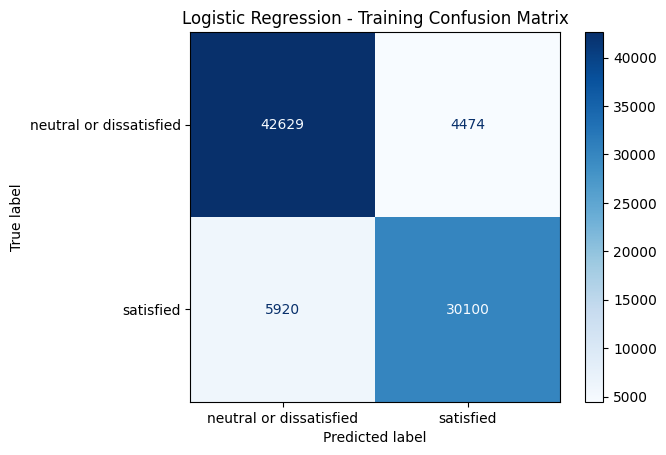

In [39]:
# Logistic Regression - Training Confusion Matrix

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    cmap='Blues',
    values_format='d'
)

plt.title('Logistic Regression - Training Confusion Matrix')
plt.show()

In [40]:
# Decision Tree Model

from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [41]:
# Decision Tree Training Accuracy

tree_model.score(X_train, y_train)

1.0

In [42]:
# Decision Tree - Training Performance (Potential Overfitting)

y_train_pred_tree = tree_model.predict(X_train)

print(classification_report(y_train, y_train_pred_tree))

# Decision Tree - Training Performance
# 100% training accuracy may indicate overfitting.

                         precision    recall  f1-score   support

neutral or dissatisfied       1.00      1.00      1.00     47103
              satisfied       1.00      1.00      1.00     36020

               accuracy                           1.00     83123
              macro avg       1.00      1.00      1.00     83123
           weighted avg       1.00      1.00      1.00     83123



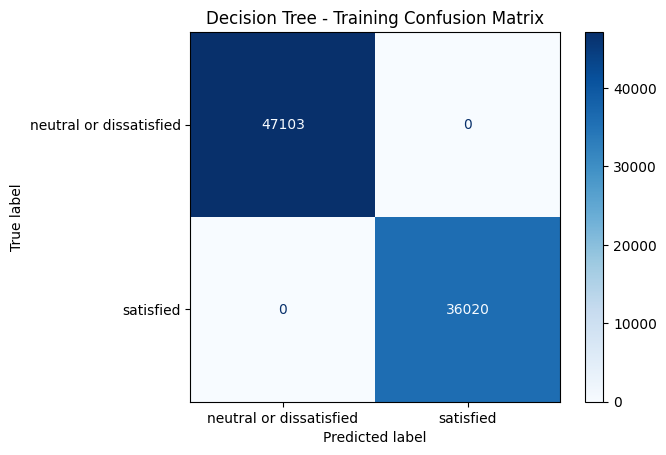

In [43]:
# Decision Tree - Training Confusion Matrix

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred_tree,
    cmap='Blues',
    values_format='d'
)

plt.title('Decision Tree - Training Confusion Matrix')
plt.show()

In [44]:
######### Model Evaluation #########

In [45]:
# Logistic Regression - Test Accuracy

log_model.score(X_test_scaled, y_test)

0.8763774601799721

In [46]:
# Decision Tree - Test Accuracy

tree_model.score(X_test, y_test)

0.9461527356720081

In [47]:
# Logistic Regression - Test Performance

y_test_pred_log = log_model.predict(X_test_scaled)

print(classification_report(y_test, y_test_pred_log))

                         precision    recall  f1-score   support

neutral or dissatisfied       0.88      0.90      0.89     11776
              satisfied       0.87      0.84      0.86      9005

               accuracy                           0.88     20781
              macro avg       0.88      0.87      0.87     20781
           weighted avg       0.88      0.88      0.88     20781



In [48]:
# Decision Tree - Test Performance

y_test_pred_tree = tree_model.predict(X_test)

print(classification_report(y_test, y_test_pred_tree))

                         precision    recall  f1-score   support

neutral or dissatisfied       0.96      0.95      0.95     11776
              satisfied       0.93      0.95      0.94      9005

               accuracy                           0.95     20781
              macro avg       0.94      0.95      0.95     20781
           weighted avg       0.95      0.95      0.95     20781



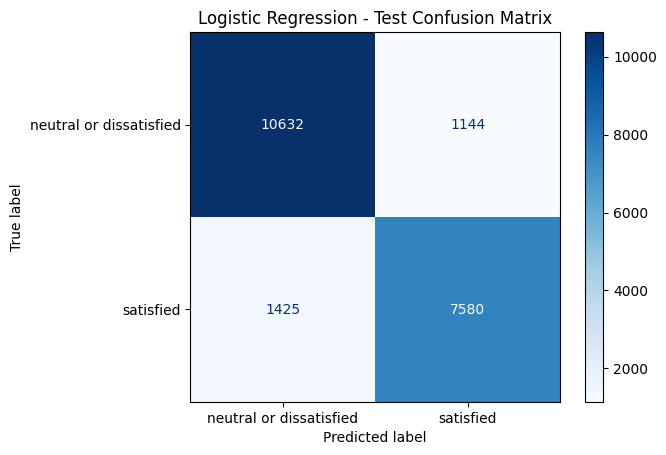

In [49]:
# Logistic Regression - Test Confusion Matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_log,
    cmap='Blues',
    values_format='d'
)

plt.title('Logistic Regression - Test Confusion Matrix')
plt.show()

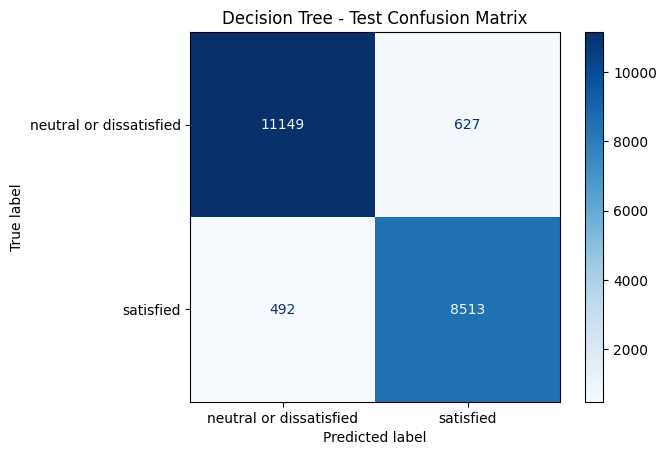

In [50]:
# Decision Tree - Test Confusion Matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_tree,
    cmap='Blues',
    values_format='d'
)

plt.title('Decision Tree - Test Confusion Matrix')
plt.show()

In [51]:
## Model Improvement – Decision Tree ##

In [52]:
# Decision Tree - Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV

params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15],
    'min_samples_leaf': [2, 5, 10]
}

tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

tree_grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [5, 10, 15],
                         'min_samples_leaf': [2, 5, 10]},
             scoring='accuracy')

In [53]:
# Decision Tree - Best Parameters

tree_grid.best_params_

{'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 10}

In [54]:
# Decision Tree - Best Cross Validation Accuracy

tree_grid.best_score_

np.float64(0.9521071272985159)

In [55]:
# Tuned Decision Tree - Training Accuracy

best_tree = tree_grid.best_estimator_

best_tree.score(X_train, y_train)

0.9653645802004259

In [56]:
# Tuned Decision Tree - Training Performance

y_train_pred_tuned = best_tree.predict(X_train)

print(classification_report(y_train, y_train_pred_tuned))

                         precision    recall  f1-score   support

neutral or dissatisfied       0.96      0.98      0.97     47103
              satisfied       0.98      0.94      0.96     36020

               accuracy                           0.97     83123
              macro avg       0.97      0.96      0.96     83123
           weighted avg       0.97      0.97      0.97     83123



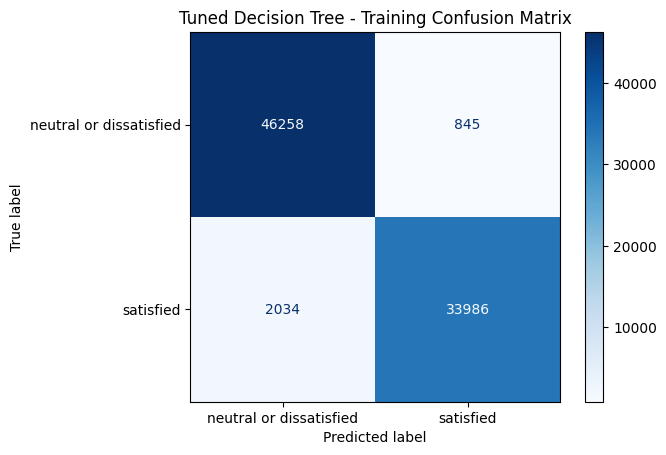

In [57]:
# Tuned Decision Tree - Training Confusion Matrix

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred_tuned,
    cmap='Blues',
    values_format='d'
)

plt.title('Tuned Decision Tree - Training Confusion Matrix')
plt.show()

In [58]:
# Tuned Decision Tree - Test Accuracy

best_tree.score(X_test, y_test)

0.9523603291468168

In [59]:
# Tuned Decision Tree - Test Performance

y_test_pred_tuned = best_tree.predict(X_test)

print(classification_report(y_test, y_test_pred_tuned))

                         precision    recall  f1-score   support

neutral or dissatisfied       0.95      0.97      0.96     11776
              satisfied       0.95      0.93      0.94      9005

               accuracy                           0.95     20781
              macro avg       0.95      0.95      0.95     20781
           weighted avg       0.95      0.95      0.95     20781



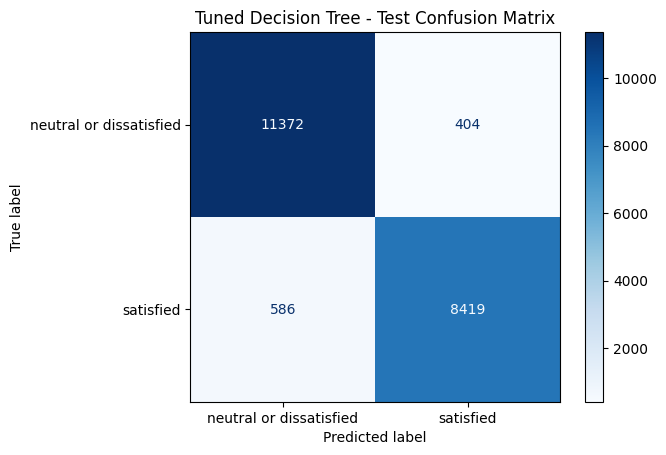

In [60]:
# Tuned Decision Tree - Test Confusion Matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_tuned,
    cmap='Blues',
    values_format='d'
)

plt.title('Tuned Decision Tree - Test Confusion Matrix')
plt.show()

In [61]:
# Tuned Decision Tree - Feature Importance

feature_importance = pd.Series(
    best_tree.feature_importances_,
    index=X_train.columns
)

feature_importance.sort_values(ascending=False).head(10)

,0
Online boarding,0.400091
Inflight wifi service,0.196556
Type of Travel_Business travel,0.155676
Inflight entertainment,0.050189
Checkin service,0.026958
Customer Type_disloyal Customer,0.025800
Class_Business,0.022691
Gate location,0.019756
Customer Type_Loyal Customer,0.016974
Baggage handling,0.013033


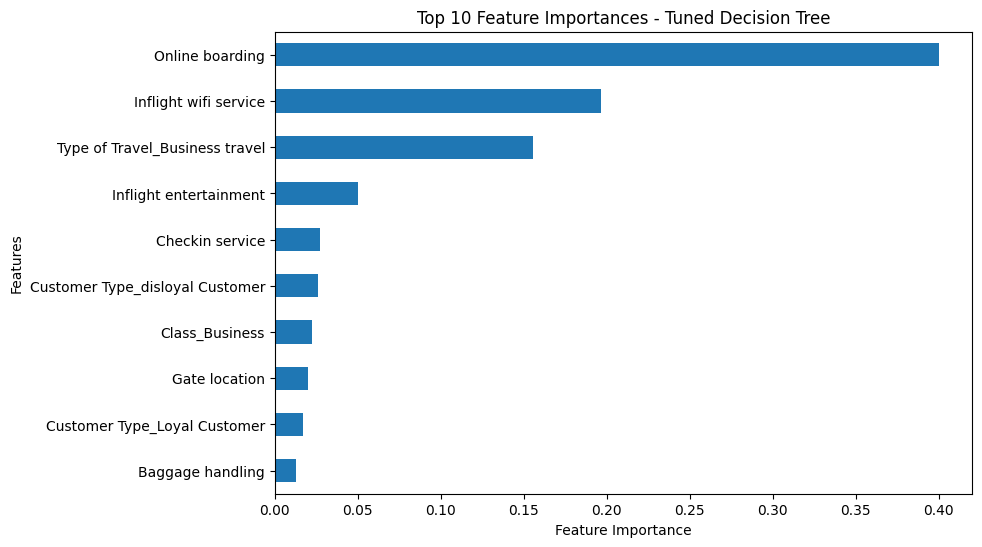

In [62]:
# Tuned Decision Tree - Feature Importance Visualization

top_features = feature_importance.sort_values(ascending=False).head(10)

top_features.sort_values().plot(kind='barh', figsize=(9, 6))

plt.title('Top 10 Feature Importances - Tuned Decision Tree')
plt.xlabel('Feature Importance')
plt.ylabel('Features')

plt.show()

In [63]:
##########################################

In [64]:
# Save Tuned Decision Tree Model

import joblib

joblib.dump(best_tree, 'decision_tree_model.pkl')
joblib.dump(X_train.columns.tolist(), 'feature_columns.pkl')

['feature_columns.pkl']

In [65]:
# Check Saved Files

import os

os.path.exists('decision_tree_model.pkl'), os.path.exists('feature_columns.pkl')

(True, True)

In [66]:
# Check model files before Streamlit deployment

import joblib

model = joblib.load('decision_tree_model.pkl')
feature_columns = joblib.load('feature_columns.pkl')

print("Model:", type(model).__name__)
print("Number of Features:", len(feature_columns))

Model: DecisionTreeClassifier
Number of Features: 27


In [67]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Load model and feature columns
model = joblib.load('decision_tree_model.pkl')
feature_columns = joblib.load('feature_columns.pkl')

st.title('Airline Passenger Satisfaction Prediction')
st.write('Predict passenger satisfaction using a Decision Tree model.')

# Passenger Information
st.header('Passenger Information')

gender = st.selectbox('Gender', ['Male', 'Female'])
customer_type = st.selectbox('Customer Type', ['Loyal Customer', 'disloyal Customer'])
age = st.number_input('Age', min_value=7, max_value=85, value=30)
travel_type = st.selectbox('Type of Travel', ['Business travel', 'Personal Travel'])
travel_class = st.selectbox('Class', ['Business', 'Eco', 'Eco Plus'])
flight_distance = st.number_input('Flight Distance', min_value=0, value=1000)

# Service Ratings
st.header('Service Ratings')

rating_features = [
    'Inflight wifi service',
    'Departure/Arrival time convenient',
    'Ease of Online booking',
    'Gate location',
    'Food and drink',
    'Online boarding',
    'Seat comfort',
    'Inflight entertainment',
    'On-board service',
    'Leg room service',
    'Baggage handling',
    'Checkin service',
    'Inflight service',
    'Cleanliness'
]

ratings = {}

for feature in rating_features:
    ratings[feature] = st.slider(feature, 0, 5, 3)

# Flight Delays
st.header('Flight Delays')

departure_delay = st.number_input(
    'Departure Delay in Minutes', min_value=0, value=0
)

arrival_delay = st.number_input(
    'Arrival Delay in Minutes', min_value=0, value=0
)

# Create input data
input_data = {
    'Gender': gender,
    'Customer Type': customer_type,
    'Age': age,
    'Type of Travel': travel_type,
    'Class': travel_class,
    'Flight Distance': flight_distance,
    'Departure Delay in Minutes': departure_delay,
    'Arrival Delay in Minutes': arrival_delay
}

input_data.update(ratings)

input_df = pd.DataFrame([input_data])

# One-Hot Encoding
input_encoded = pd.DataFrame(0, index=[0], columns=feature_columns)

for col in input_df.columns:
    if col in input_encoded.columns:
        input_encoded[col] = input_df[col].values
    else:
        encoded_col = col + '_' + str(input_df[col].iloc[0])
        if encoded_col in input_encoded.columns:
            input_encoded[encoded_col] = 1

# Prediction
if st.button('Predict Satisfaction'):
    prediction = model.predict(input_encoded)

    st.subheader('Prediction Result')
    st.write(prediction[0])

Writing app.py


In [68]:
# Check app.py

import os

os.path.exists('app.py')

True

In [69]:
%%writefile requirements.txt
streamlit
pandas
scikit-learn
joblib

Writing requirements.txt


In [70]:
# Check deployment files

import os

files = [
    'app.py',
    'requirements.txt',
    'decision_tree_model.pkl',
    'feature_columns.pkl'
]

for file in files:
    print(file, os.path.exists(file))

app.py True
requirements.txt True
decision_tree_model.pkl True
feature_columns.pkl True


In [71]:
# Test saved model prediction

import joblib

model = joblib.load('decision_tree_model.pkl')
feature_columns = joblib.load('feature_columns.pkl')

sample = X_test.iloc[[0]].reindex(columns=feature_columns)

prediction = model.predict(sample)

print("Input Features:", sample.shape[1])
print("Prediction:", prediction[0])
print("Actual Satisfaction:", y_test.iloc[0])

Input Features: 27
Prediction: neutral or dissatisfied
Actual Satisfaction: neutral or dissatisfied


In [72]:
# Test Streamlit input encoding

import pandas as pd
import joblib

feature_columns = joblib.load('feature_columns.pkl')

# Use one passenger from the original test data
sample_input = X_test.iloc[[0]]

# Check feature structure
print("Number of Features:", sample_input.shape[1])
print("Missing Features:", set(feature_columns) - set(sample_input.columns))
print("Extra Features:", set(sample_input.columns) - set(feature_columns))

Number of Features: 27
Missing Features: set()
Extra Features: set()


In [73]:
# Randomly select a passenger from the test dataset

import random

sample_index = random.choice(X_test.index.tolist())

sample_passenger = X.loc[sample_index]
sample_encoded = X_test.loc[[sample_index]]

prediction = best_tree.predict(sample_encoded)[0]

print("Passenger Information:")
print(sample_passenger.to_string())

print("\nColab Prediction:", prediction)
print("Actual Satisfaction:", y_test.loc[sample_index])

Passenger Information:
Gender                                          Male
Customer Type                         Loyal Customer
Age                                               13
Type of Travel                       Personal Travel
Class                                            Eco
Flight Distance                                 1102
Inflight wifi service                              3
Departure/Arrival time convenient                  3
Ease of Online booking                             3
Gate location                                      1
Food and drink                                     5
Online boarding                                    3
Seat comfort                                       5
Inflight entertainment                             5
On-board service                                   4
Leg room service                                   5
Baggage handling                                   3
Checkin service                                    5
Inflight service       